In [1]:
from __future__ import print_function
import os
import cv2 
import numpy as np
import pandas as pd   
import matplotlib.pyplot as plt
from PIL import Image
from pillow_heif import register_heif_opener
import random
import xgboost as xgb
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.model_selection import KFold, cross_val_score, cross_validate
from sklearn.metrics import make_scorer, accuracy_score, precision_score, recall_score, f1_score
from sklearn.model_selection import StratifiedKFold
from skimage.feature import local_binary_pattern
import skimage.feature as feature

import warnings
import mahotas
warnings.filterwarnings("ignore")

In [2]:
GROUP = "C4"
DTYPE="GLCM"
DIR_TRAIN = "DATA/TRAINING/"
GROUP_path = DIR_TRAIN+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path = os.listdir(GROUP_path)
resume = []
data_path = []
for HH in HH_path:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT = pd.DataFrame(resume)    # values
pdDT.columns = ["Humidity", "numberImages", "pathImages"]
pdDT

,Humidity,numberImages,pathImages
0,C4_10,25,"[DATA/TRAINING/C4/C4_10/IMG_6597.HEIC, DATA/TR..."
1,C4_11,27,"[DATA/TRAINING/C4/C4_11/IMG_6727.HEIC, DATA/TR..."
2,C4_12,27,"[DATA/TRAINING/C4/C4_12/IMG_6857.HEIC, DATA/TR..."
3,C4_13,30,"[DATA/TRAINING/C4/C4_13/IMG_6998.HEIC, DATA/TR..."
4,C4_14,27,"[DATA/TRAINING/C4/C4_14/IMG_7250.HEIC, DATA/TR..."
5,C4_15,25,"[DATA/TRAINING/C4/C4_15/IMG_7388.HEIC, DATA/TR..."
6,C4_16,28,"[DATA/TRAINING/C4/C4_16/IMG_7517.HEIC, DATA/TR..."


In [3]:
def read_imgHEIC(pic_path):
    register_heif_opener(); im = Image.open(pic_path)
    return cv2.cvtColor(np.array(im), cv2.COLOR_RGB2BGR)

In [4]:
def flip_image_vertical(image):
    height, width, channels = image.shape
    if(height < width):
        image = cv2.rotate(image, cv2.ROTATE_90_CLOCKWISE)
    return image

In [5]:
def resize_image(img, scale_percent = 10):
     # percent of original size
    width = int(img.shape[1] * scale_percent / 100)
    height = int(img.shape[0] * scale_percent / 100)
    dim = (width, height)
    #print(dim)
    # resize image
    resized = cv2.resize(img, dim, interpolation = cv2.INTER_AREA)
    return resized

Text(0.5, 1.0, '16% IMG_7565.HEIC')

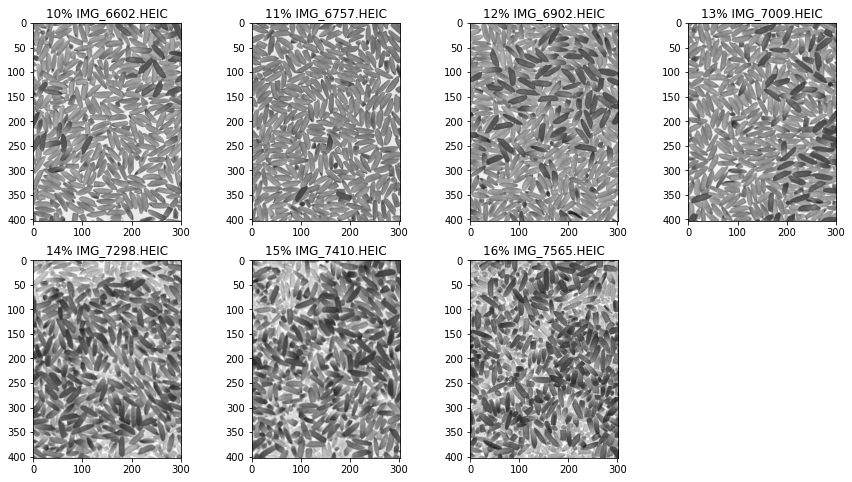

In [6]:
fig=plt.figure(figsize=(15, 8)) 
ax1 = fig.add_subplot(2,4,1); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[0][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax1.imshow(image); ax1.set_title("10% " + data_path[0][path_image].split("/")[4])
ax2 = fig.add_subplot(2,4,2); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[1][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax2.imshow(image); ax2.set_title("11% "+ data_path[1][path_image].split("/")[4])
ax3 = fig.add_subplot(2,4,3); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[2][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax3.imshow(image); ax3.set_title("12% "+ data_path[2][path_image].split("/")[4])
ax4 = fig.add_subplot(2,4,4); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[3][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax4.imshow(image); ax4.set_title("13% "+ data_path[3][path_image].split("/")[4])
ax5 = fig.add_subplot(2,4,5); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[4][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax5.imshow(image); ax5.set_title("14% "+ data_path[4][path_image].split("/")[4])
ax6 = fig.add_subplot(2,4,6); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[5][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax6.imshow(image); ax6.set_title("15% "+ data_path[5][path_image].split("/")[4])
ax7 = fig.add_subplot(2,4,7); path_image= random.randint(0, 25)
image = read_imgHEIC(data_path[6][path_image]); image = flip_image_vertical(image); image = resize_image(image)
ax7.imshow(image); ax7.set_title("16% "+ data_path[6][path_image].split("/")[4])

In [17]:
#Parameters
HH = ['10', '11', '12', '13', '14', '15', '16']
#bins=44; #width=2024; height=3032; 
scale=25
dtHH=[]
for lstImgs, H in zip(data_path, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        #print(image.shape)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        
        graycom = feature.graycomatrix(gray, [1], [0, np.pi/4, np.pi/2, 3*np.pi/4], levels=256)
        # Find the GLCM properties
        contrast = feature.graycoprops(graycom, 'contrast')
        dissimilarity = feature.graycoprops(graycom, 'dissimilarity')
        homogeneity = feature.graycoprops(graycom, 'homogeneity')
        energy = feature.graycoprops(graycom, 'energy')
        correlation = feature.graycoprops(graycom, 'correlation')
        ASM = feature.graycoprops(graycom, 'ASM')
        #contrast+dissimilarity+homogeneity+energy+correlation+ASM
        features = list(contrast[0])+list(dissimilarity[0])+list(homogeneity[0])+list(energy[0])+list(correlation[0])+list(ASM[0])
        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH.append(pdGrayFeatures)

In [18]:
result = pd.concat(dtHH)

DIR= "FEATURES/ORIGINAL/GLOBAL/TRAINING/"; 
result.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result.head(10)

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,scale,height,width,channels,IMAGENAME,HUMIDITY
0,269.373392,435.116850,238.408391,444.234686,7.853256,10.057097,7.361206,10.170902,0.240110,0.203006,...,0.000626,0.000506,0.000647,0.000503,25,1008,756,3,IMG_6597.HEIC,10
1,252.920214,377.933224,266.238565,513.620441,7.579126,9.189547,7.686819,10.886774,0.248941,0.219289,...,0.000610,0.000515,0.000607,0.000461,25,1008,756,3,IMG_6598.HEIC,10
2,257.743070,389.034784,243.375857,484.023621,7.595149,9.392029,7.247370,10.592637,0.244244,0.210476,...,0.000486,0.000399,0.000488,0.000365,25,1008,756,3,IMG_6599.HEIC,10
3,243.392433,446.550505,277.204636,457.652885,7.383729,10.140028,7.994772,10.334788,0.248054,0.201239,...,0.000649,0.000499,0.000602,0.000492,25,1008,756,3,IMG_6600.HEIC,10
4,289.023393,469.707014,240.184397,447.425055,7.941710,10.191219,7.228251,9.986189,0.248148,0.209900,...,0.000707,0.000566,0.000736,0.000581,25,1008,756,3,IMG_6601.HEIC,10
5,265.882885,497.179192,291.232266,468.433077,7.557457,10.564507,7.997573,10.231295,0.254322,0.202966,...,0.000714,0.000544,0.000678,0.000557,25,1008,756,3,IMG_6602.HEIC,10
6,274.847576,491.139089,255.074418,431.746791,7.571727,10.347333,7.450203,9.770501,0.261635,0.212266,...,0.000706,0.000542,0.000699,0.000563,25,1008,756,3,IMG_6603.HEIC,10
7,282.723117,529.284191,295.130670,473.915821,7.713220,10.706642,7.812582,9.988694,0.254087,0.205098,...,0.000863,0.000669,0.000854,0.000703,25,1008,756,3,IMG_6604.HEIC,10
8,288.458475,525.167278,302.231471,505.628275,8.063035,11.107874,8.186553,10.744738,0.239318,0.192931,...,0.000735,0.000569,0.000726,0.000586,25,1008,756,3,IMG_6605.HEIC,10
9,283.890224,466.795149,299.912123,544.816441,7.900076,10.270767,8.121202,11.075268,0.241509,0.201847,...,0.000724,0.000582,0.000707,0.000563,25,1008,756,3,IMG_6606.HEIC,10


# Classification

In [154]:
dtFeatures=result#.drop(['IMAGENAME'], axis=1)
#dtFeatures.head()
X = dtFeatures.values[:, :-6]
#X

In [155]:

# Normalization -> values[0-1]
scaler = MinMaxScaler()
X_scale = scaler.fit_transform(X)     
y = dtFeatures.values[:, -1]
#y

In [156]:
def compute_classification_metrics(y_pred, y_test):
    acc = np.sum(y_pred == y_test) / float(len(y_test))
    precision =np.mean(precision_score(y_test, y_pred, average=None, zero_division=1))
    recall =np.mean(recall_score(y_test, y_pred, average=None, zero_division=1))
    F1 = 2 * (precision * recall) / (precision + recall)
    return acc, precision, recall, F1

In [157]:
def get_CV_CLASSIFICATION_MODELS(model, X, y, rescale=False):
    dt_lg_test=[]  
    if rescale==True:
        y=y-10
        #print(y)
    kfold = StratifiedKFold(n_splits=10, shuffle=True)
    k_fold=1
    for train_index , test_index in kfold.split(X, y):

        X_train , X_test = X[train_index], X[test_index]
        y_train , y_test = y[train_index], y[test_index]
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)  # predict label

        [acc, precision, recall, F1] = compute_classification_metrics(y_pred, y_test)
        dt_lg_test.append([k_fold, acc, precision, recall, F1])
        k_fold=k_fold+1
    return dt_lg_test

#### Random Forest Classifier

In [158]:
modelRFC=RandomForestClassifier(n_estimators=1000) 
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelRFC, X_scale, y)
modelName="RF_C"

In [159]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.684211,0.630952,0.714286,0.670038,GLCM,C4,RF_C,3,120,90,3
1,2,0.684211,0.750000,0.690476,0.719008,GLCM,C4,RF_C,3,120,90,3
2,3,0.473684,0.464286,0.500000,0.481481,GLCM,C4,RF_C,3,120,90,3
3,4,0.526316,0.521429,0.547619,0.534203,GLCM,C4,RF_C,3,120,90,3
4,5,0.473684,0.342857,0.476190,0.398671,GLCM,C4,RF_C,3,120,90,3
5,6,0.684211,0.771429,0.714286,0.741758,GLCM,C4,RF_C,3,120,90,3
6,7,0.631579,0.630952,0.619048,0.624943,GLCM,C4,RF_C,3,120,90,3
7,8,0.684211,0.714286,0.690476,0.702179,GLCM,C4,RF_C,3,120,90,3
8,9,0.631579,0.657143,0.642857,0.649922,GLCM,C4,RF_C,3,120,90,3
9,10,0.611111,0.714286,0.619048,0.663265,GLCM,C4,RF_C,3,120,90,3


In [160]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()
#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultRF=result
resultRF

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C4,RF_C,0.60848,0.621429,0.618547,0.619762


### MLP Classifier

In [161]:
# Import MLPClassifer 
from sklearn.neural_network import MLPClassifier

In [162]:
modelMLPC = MLPClassifier(max_iter=500)
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelMLPC, X_scale, y)
modelName='MLP_C'

In [163]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.526316,0.604762,0.500000,0.547414,GLCM,C4,MLP_C,3,120,90,3
1,2,0.473684,0.523810,0.500000,0.511628,GLCM,C4,MLP_C,3,120,90,3
2,3,0.684211,0.747619,0.690476,0.717912,GLCM,C4,MLP_C,3,120,90,3
3,4,0.578947,0.557143,0.571429,0.564195,GLCM,C4,MLP_C,3,120,90,3
4,5,0.631579,0.583333,0.595238,0.589226,GLCM,C4,MLP_C,3,120,90,3
5,6,0.684211,0.735714,0.690476,0.712378,GLCM,C4,MLP_C,3,120,90,3
6,7,0.684211,0.747619,0.714286,0.730572,GLCM,C4,MLP_C,3,120,90,3
7,8,0.473684,0.416667,0.452381,0.433790,GLCM,C4,MLP_C,3,120,90,3
8,9,0.526316,0.571429,0.547619,0.559271,GLCM,C4,MLP_C,3,120,90,3
9,10,0.611111,0.761905,0.619048,0.683087,GLCM,C4,MLP_C,3,120,90,3


In [164]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C4,MLP_C,0.587427,0.588095,0.604947,0.625


### XGBoost Classifier

In [165]:
modelXGBC = xgb.XGBClassifier()
y = np.array([int(x) for x in y])
lst_FoldTrain= get_CV_CLASSIFICATION_MODELS(modelXGBC, X_scale, y, True)
modelName='XGB_C'

In [166]:
dtFoldTrain = pd.DataFrame(lst_FoldTrain)
dtFoldTrain.columns = ["k_fold", 'accuracy', 'F1', 'precision', 'recall']
dtFoldTrain["DTYPE"]=DTYPE; dtFoldTrain["GROUP"]=GROUP;  dtFoldTrain["MODEL"]=modelName
dtFoldTrain["scale"]=scale; 
dtFoldTrain["height"]=height; dtFoldTrain["width"]=width; dtFoldTrain["channels"]=channels;
dtFoldTrain.to_csv('RESULTS/GLOBAL/CV/'+str(scale)+'/CV_'+GROUP+"_"+DTYPE+'_'+modelName+'.csv', index=False)
dtFoldTrain

,k_fold,accuracy,F1,precision,recall,DTYPE,GROUP,MODEL,scale,height,width,channels
0,1,0.473684,0.500000,0.476190,0.487805,GLCM,C4,XGB_C,3,120,90,3
1,2,0.473684,0.583333,0.476190,0.524345,GLCM,C4,XGB_C,3,120,90,3
2,3,0.631579,0.585714,0.619048,0.601920,GLCM,C4,XGB_C,3,120,90,3
3,4,0.631579,0.723810,0.666667,0.694064,GLCM,C4,XGB_C,3,120,90,3
4,5,0.684211,0.726190,0.690476,0.707883,GLCM,C4,XGB_C,3,120,90,3
5,6,0.578947,0.571429,0.571429,0.571429,GLCM,C4,XGB_C,3,120,90,3
6,7,0.368421,0.440476,0.333333,0.379487,GLCM,C4,XGB_C,3,120,90,3
7,8,0.578947,0.704762,0.547619,0.616332,GLCM,C4,XGB_C,3,120,90,3
8,9,0.684211,0.785714,0.642857,0.707143,GLCM,C4,XGB_C,3,120,90,3
9,10,0.777778,0.845238,0.785714,0.814390,GLCM,C4,XGB_C,3,120,90,3


In [167]:
result = dtFoldTrain.groupby(["DTYPE", "GROUP", "MODEL"]).aggregate({'accuracy':'mean','precision':'mean', 
                                                            'recall':'mean', 'F1':'mean'})
result = result.reset_index()#result.to_csv('RESULTS/GLOBAL/'+TYPE+'/'+GR+'_'+TYPE+'_'+modelName+'_'+str(bins)+'_bins.csv', index=False)
resultMLP=result
resultMLP

,DTYPE,GROUP,MODEL,accuracy,precision,recall,F1
0,GLCM,C4,XGB_C,0.588304,0.580952,0.61048,0.646667


# External validation

In [168]:
DIR_TEST = "DATA/TEST/"
GROUP_path = DIR_TEST+GROUP+"/"
# ['10', '11', '12', '13', '14', '15', '16']
HH_path_test = os.listdir(GROUP_path)
resume = []
data_path_test = []
for HH in HH_path_test:
    path_GHH = GROUP_path+HH+"/"
    images = os.listdir(path_GHH)
    path_images = [GROUP_path+HH+"/"+x for x in images]
    data_path_test.append(path_images)
    resume.append([HH, len(path_images), path_images])
pdDT_test = pd.DataFrame(resume)    # values
pdDT_test.columns = ["Humidity", "numberImages", "pathImages"]
pdDT_test

,Humidity,numberImages,pathImages
0,C4_10,5,"[DATA/TEST/C4/C4_10/IMG_6593.HEIC, DATA/TEST/C..."
1,C4_11,5,"[DATA/TEST/C4/C4_11/IMG_6718.HEIC, DATA/TEST/C..."
2,C4_12,5,"[DATA/TEST/C4/C4_12/IMG_6846.HEIC, DATA/TEST/C..."
3,C4_13,5,"[DATA/TEST/C4/C4_13/IMG_6983.HEIC, DATA/TEST/C..."
4,C4_14,5,"[DATA/TEST/C4/C4_14/IMG_7240.HEIC, DATA/TEST/C..."
5,C4_15,5,"[DATA/TEST/C4/C4_15/IMG_7378.HEIC, DATA/TEST/C..."
6,C4_16,5,"[DATA/TEST/C4/C4_16/IMG_7507.HEIC, DATA/TEST/C..."


In [169]:
HH=['10', '11', '12', '13', '14', '15', '16']

In [170]:
dtHH_test=[]
for lstImgs, H in zip(data_path_test, HH):
    arr_img_hist=[]; name_images = []
    for im_path in lstImgs: 
        image = read_imgHEIC(im_path) ; image = flip_image_vertical(image)
        image = resize_image(image, scale)
        #imCrop=centerCrop(image, width, height)
        [height, width, channels] = image.shape
        nameImage=im_path.split("/")[-1]; name_images.append(nameImage)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        
        graycom = feature.graycomatrix(gray, [1], [0, np.pi/4, np.pi/2, 3*np.pi/4], levels=256)
        # Find the GLCM properties
        contrast = feature.graycoprops(graycom, 'contrast')
        dissimilarity = feature.graycoprops(graycom, 'dissimilarity')
        homogeneity = feature.graycoprops(graycom, 'homogeneity')
        energy = feature.graycoprops(graycom, 'energy')
        correlation = feature.graycoprops(graycom, 'correlation')
        ASM = feature.graycoprops(graycom, 'ASM')
        #contrast+dissimilarity+homogeneity+energy+correlation+ASM
        features = list(contrast[0])+list(dissimilarity[0])+list(homogeneity[0])+list(energy[0])+list(correlation[0])+list(ASM[0])

        arr_img_hist.append(features)
    pdGrayFeatures = pd.DataFrame(arr_img_hist)
    pdGrayFeatures["scale"] = scale
    pdGrayFeatures["height"] = height
    pdGrayFeatures["width"] = width
    pdGrayFeatures["channels"] = channels
    pdGrayFeatures["IMAGENAME"] = name_images
    pdGrayFeatures["HUMIDITY"] = H
    dtHH_test.append(pdGrayFeatures)

In [171]:
result_test = pd.concat(dtHH_test)

DIR= "FEATURES/ORIGINAL/GLOBAL/TESTING/"; 
result_test.to_csv(DIR+'features_s'+str(scale)+'_'+GROUP+'_'+DTYPE+'.csv', index=False)
result_test.head(10)

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,scale,height,width,channels,IMAGENAME,HUMIDITY
0,942.979120,1414.662638,907.099160,1277.649608,21.186610,26.839958,20.555929,25.173921,0.081402,0.061839,...,0.000239,0.000206,0.000242,0.000214,3,120,90,3,IMG_6593.HEIC,10
1,989.717603,1358.799830,840.358263,1290.085733,21.829401,26.160986,19.577498,25.678973,0.076669,0.060815,...,0.000245,0.000219,0.000264,0.000219,3,120,90,3,IMG_6594.HEIC,10
2,946.712079,1355.267302,857.697946,1210.327353,21.221255,26.110282,19.923716,24.521481,0.082199,0.063097,...,0.000265,0.000235,0.000275,0.000245,3,120,90,3,IMG_6595.HEIC,10
3,995.793914,1407.956189,956.029879,1397.608536,21.559831,26.263809,20.883473,26.093098,0.090243,0.074220,...,0.000283,0.000248,0.000295,0.000254,3,120,90,3,IMG_6596.HEIC,10
4,1036.829775,1425.391842,1079.509991,1605.484468,21.839700,26.285242,22.275257,28.349920,0.092285,0.072668,...,0.000328,0.000281,0.000315,0.000268,3,120,90,3,IMG_660.HEIC,10
0,818.371723,1245.210556,951.910551,1347.116797,19.525468,24.928430,21.301401,26.376357,0.087812,0.063489,...,0.000245,0.000211,0.000229,0.000199,3,120,90,3,IMG_6718.HEIC,11
1,871.655431,1195.477575,897.856956,1408.418657,20.462734,24.672552,20.773109,27.253517,0.076460,0.064112,...,0.000229,0.000206,0.000227,0.000195,3,120,90,3,IMG_6720.HEIC,11
2,912.679307,1192.412048,900.790570,1354.563686,20.618071,23.886507,20.305415,26.088755,0.077503,0.068721,...,0.000296,0.000270,0.000299,0.000254,3,120,90,3,IMG_6723.HEIC,11
3,924.679869,1217.362478,810.984500,1233.893872,20.881367,24.574261,19.290756,24.949485,0.076589,0.064852,...,0.000280,0.000254,0.000289,0.000247,3,120,90,3,IMG_6725.HEIC,11
4,923.450094,1215.383533,813.408123,1233.626664,20.805150,24.482202,19.234080,24.863752,0.080039,0.066063,...,0.000285,0.000259,0.000295,0.000253,3,120,90,3,IMG_6726.HEIC,11


In [172]:
dtFeaturesTest=result_test#.drop(['IMAGENAME'], axis=1)
#dtFeaturesTest.head()

In [173]:
X_test = dtFeaturesTest.values[:, :-6]
#X_test

In [174]:
X_test_scale = scaler.transform(X_test)     
y_test = dtFeaturesTest.values[:, -1]
y_test

array(['10', '10', '10', '10', '10', '11', '11', '11', '11', '11', '12',
       '12', '12', '12', '12', '13', '13', '13', '13', '13', '14', '14',
       '14', '14', '14', '15', '15', '15', '15', '15', '16', '16', '16',
       '16', '16'], dtype=object)

## RFC

In [175]:
y_pred = modelRFC.predict(X_test_scale)  # predict label

In [176]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.60      0.75         5
     Class 1       0.50      0.40      0.44         5
     Class 2       0.50      0.80      0.62         5
     Class 3       0.50      0.60      0.55         5
     Class 4       0.00      0.00      0.00         5
     Class 5       0.43      0.60      0.50         5
     Class 6       0.80      0.80      0.80         5

    accuracy                           0.54        35
   macro avg       0.53      0.54      0.52        35
weighted avg       0.53      0.54      0.52        35



## MLP

In [177]:
y_pred = modelMLPC.predict(X_test_scale)  # predict label

In [178]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
res = classification_report(y_test, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.80      0.89         5
     Class 1       0.75      0.60      0.67         5
     Class 2       0.40      0.40      0.40         5
     Class 3       0.38      0.60      0.46         5
     Class 4       0.50      0.20      0.29         5
     Class 5       0.50      0.60      0.55         5
     Class 6       0.67      0.80      0.73         5

    accuracy                           0.57        35
   macro avg       0.60      0.57      0.57        35
weighted avg       0.60      0.57      0.57        35



## XGBC

In [179]:
y_pred = modelXGBC.predict(X_test_scale) 

In [180]:
num_classes=7
target_names = ["Class {}".format(i) for i in range(num_classes)]
y_test = np.array([int(x) for x in y_test])
res = classification_report(y_test-10, y_pred, target_names=target_names)
print(res)

              precision    recall  f1-score   support

     Class 0       1.00      0.40      0.57         5
     Class 1       0.50      0.60      0.55         5
     Class 2       0.29      0.40      0.33         5
     Class 3       0.50      0.60      0.55         5
     Class 4       0.25      0.20      0.22         5
     Class 5       0.60      0.60      0.60         5
     Class 6       0.80      0.80      0.80         5

    accuracy                           0.51        35
   macro avg       0.56      0.51      0.52        35
weighted avg       0.56      0.51      0.52        35

